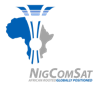 &nbsp;&nbsp; 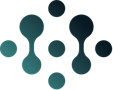

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/main/Jasons-Restructure/week-2/day-1-trend-season-noise/4-instructor-only/W2D1-solution.ipynb)

> 🧑🏾‍🏫 **INSTRUCTOR SOLUTION.** Every blank is filled in. Don't share this with participants before the session ends.

# 🔧 Week 2 · Day 1: Take It Apart: Trend, Season and Noise

**Today:** one line on a chart is really three stories added together. You'll pull them apart, measure each one, and read the leftovers, where faults hide.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (click it, then **Shift + Enter**) |
| ✍️ | Your turn: replace every `___` with your answer |
| ✅ / ❌ | The check tells you if you got it right, with a hint if not |
| 🌶️ | Bonus task for fast finishers |

> ## ⚠️ Do this FIRST: **File → Save a copy in Drive**
> Work in your copy (the new tab), not the original.

**Rule book:** keep `W2D1-rulebook.pdf` open next to you.

## ▶️ STEP 0: Set up (run this once, every time you open the notebook)
You should see `✅ Ready!`. If Colab says *"This notebook was not authored by Google"*, click **Run anyway**.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
from statsmodels.tsa.seasonal import seasonal_decompose as _sd, STL as _STL

def _kam():
    return pd.read_csv(data_path("ka_band_availability_monthly"), parse_dates=["month"], index_col="month").asfreq("MS")

def _swings(x):
    x = np.asarray(x, dtype=float)
    return [x[i*12:(i+1)*12].max() - x[i*12:(i+1)*12].min() for i in range(len(x)//12)]

def _c_a1(x):
    return str(x).strip() == "MS", "\"MS\" = Month Start. Every month now has exactly one row.", \
        "Monthly data, labelled by the first day of each month. The code is two capital letters, in quotes."

def _c_a2(x):
    return int(x) == 3, "3 full rainy seasons: exactly the minimum to trust a seasonal pattern. Not a lot, but enough.", \
        "36 months ÷ 12 months per cycle."

def _c_a3(x):
    return int(x) == 12, "12! One rainy season = 12 monthly rows.", \
        "How many MONTHLY rows until the rainy season comes back?"

def _c_a4(x):
    k = _kam()["availability_pct"]
    err = float((x - k).abs().max())
    return err < 1e-9, f"Gap = {err:.0e}. Trend + seasonal + residual gives back the original EXACTLY. That's the additive model.", \
        "Add the three parts: parts.trend + parts.seasonal + parts.resid"

def _c_a5(x):
    return str(x).strip().lower() in {"8", "august", "aug"}, "August. Peak rainy season, the same story as Week 1, now measured.", \
        "parts.seasonal.idxmin() gives the date of the lowest seasonal value. Take its .month"

def _c_b1(x):
    return int(x) == 7, "7! The NOC works a weekly rhythm, so the pattern repeats every 7 daily rows.", \
        "Daily rows. What repeats every week?"

def _c_b2(x):
    tk = pd.read_csv(data_path("noc_tickets_daily"), parse_dates=["date"], index_col="date").asfreq("D")
    s = _sd(tk["tickets_raised"], period=7).seasonal
    want = s.groupby(s.index.day_name()).mean()["Sunday"]
    return abs(float(x) - want) < 0.06, f"About {want:.1f} tickets below normal on a Sunday. Even faults rest on Sunday 😄", \
        "Look up \"Sunday\" in the weekly table: weekly.loc[\"Sunday\"]"

def _c_b3(x):
    return int(x) == 12, "Right: the wrong period (12) leaves the weekend pattern stuck in the noise, so the noise is bigger.", \
        "Compare the two numbers printed above. Which period left MORE noise?"

def _c_b4(x):
    return str(x).strip().lower() == "multiplicative", "Multiplicative: the swing grows as the level grows, like a 20% fare increase.", \
        "Does the swing in the second chart stay the same size, or grow? Answer \"additive\" or \"multiplicative\"."

def _c_b5(x):
    demo = pd.read_csv(data_path("additive_multiplicative_demo"), index_col="month_index")
    ok = np.allclose(np.asarray(x, dtype=float), np.log(demo["multiplicative"].values))
    sw = _swings(x) if ok else [1, 2]
    return ok and sw[-1] / sw[0] < 1.15, f"After the log the swing barely moves ({sw[0]:.2f} → {sw[-1]:.2f}). Multiply has become add. 🪄", \
        "Use np.log(demo[\"multiplicative\"])"

def _c_b6(x):
    bus = pd.read_csv(data_path("bus_power_telemetry_hourly"), parse_dates=["timestamp"], index_col="timestamp").asfreq("h")
    want = _sd(bus["solar_array_current_a"].loc[:"2025-08-31"], period=24).resid.abs().idxmax()
    return pd.Timestamp(x) == want, f"{want:%d %b, %H:%M}: an injected solar-array dropout. The residual pointed straight at it. 🎯", \
        "aug_parts.resid.abs().idxmax() gives the TIME of the biggest leftover"

def _c_b7(x):
    return sorted(int(v) for v in x) == [3, 9], "March and September: the two eclipse seasons, one at each equinox. Not every season is one hump! 🔋", \
        "Give a list of two month numbers, e.g. [1, 2]. Read them from the seasonal bar chart."

def _c_bonus(x):
    return -1.6 < float(x) < -0.9, f"Robust STL keeps August at {float(x):+.2f}. The disaster went into the residual, not into every August. 🙌", \
        "Did you set robust=True? The answer should be close to the clean August (about −1.1)."

CHECKS = {"A1": _c_a1, "A2": _c_a2, "A3": _c_a3, "A4": _c_a4, "A5": _c_a5, "B1": _c_b1, "B2": _c_b2,
          "B3": _c_b3, "B4": _c_b4, "B5": _c_b5, "B6": _c_b6, "B7": _c_b7, "BONUS": _c_bonus}
HINTS = {"A4": "rebuilt should be parts.trend + parts.seasonal + parts.resid",
         "B6": "Pass the timestamp returned by idxmax()", "B7": "A list like [3, 9]"}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


▶️ **The tool for today.** `seasonal_decompose` lives in the `statsmodels` library, already installed in Colab. `STL` is its smarter cousin (you'll meet it in Part B).

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose, STL
print("🔧 Decomposition tools loaded")

---
# Part A: Take the Ka-band series apart (25 min) 🛰️

**The data:** `ka_band_availability_monthly`: the monthly average availability of the Ka-band Nigeria spot beam, 2023–2025.

### A1 ✍️ Declare the rhythm
This data has one row per month, labelled by the **first day** of the month. pandas' frequency code for "month start" is two capital letters. Fill it in (in quotes).

In [ ]:
FREQ = "MS"

check("A1", FREQ)

In [ ]:
assert FREQ is not None, "✍️ Do A1 first: fill in FREQ above, then run this cell again."

kam = pd.read_csv(data_path("ka_band_availability_monthly"), parse_dates=["month"], index_col="month").asfreq(FREQ)

kam["availability_pct"].plot(title="Ka-band availability, monthly: a dip every rainy season", marker="o")
plt.ylabel("% of month the link was OK")
plt.show()
print("rows:", len(kam))

### A2 ✍️ How many full cycles?
The rainy season comes once every 12 months. How many **full** rainy seasons are in this data? Use `len(kam)` and integer division `//`.

> 📖 **The rule:** you need **at least three full cycles** before you trust a seasonal pattern. One rainy season is gist. Three is a pattern.

In [ ]:
n_cycles = len(kam) // 12
print("full cycles:", n_cycles)

check("A2", n_cycles)

### A3 ✍️ Choose the period, then decompose
The **period** is how many rows until the pattern repeats. For monthly data with a yearly rainy season, what is it?

In [ ]:
PERIOD = 12

check("A3", PERIOD)

In [ ]:
assert PERIOD is not None, "✍️ Do A3 first: fill in PERIOD above."

parts = seasonal_decompose(kam["availability_pct"], model="additive", period=PERIOD)

fig = parts.plot()
fig.set_size_inches(11, 7)
plt.show()

📖 **Read the 4 panels, top to bottom:** the observed series, the **trend** (slow direction), the **seasonal** part (the same 12-month shape repeated) and the **residual** (leftovers).

Notice the trend is **missing for the first and last 6 months**. The trend is a 12-month moving average, so it needs 6 months on each side. That's normal, not missing data.

### A4 ✍️ Prove the equation
The additive model says **observed = trend + seasonal + residual**. Rebuild the series by adding the three parts, and the check measures the biggest gap from the original.

In [ ]:
rebuilt = parts.trend + parts.seasonal + parts.resid

check("A4", rebuilt)

### A5 ✍️ Which month does the season hit hardest?
`parts.seasonal.idxmin()` returns the **date** of the lowest seasonal value. Add `.month` to get the month number.

In [ ]:
worst_season_month = parts.seasonal.idxmin().month
print("worst month number:", worst_season_month)

check("A5", worst_season_month)

In [ ]:
# ▶️ the 12 seasonal numbers, one per calendar month
season = pd.Series(parts.seasonal.iloc[:12].values, index=["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
season.plot(kind="bar", title="Seasonal effect by month (points above/below the trend)")
plt.axhline(0, color="grey")
plt.show()
season.round(2)

---
# Part B: Right period, right model, read the leftovers (35 min) 🔍

### B1 ✍️ The period for daily NOC tickets
`noc_tickets_daily` has **one row per day**. The NOC works a weekly roster. What period should you use?

> 📖 The period comes from the **process**, never from a default.

In [ ]:
NOC_PERIOD = 7

check("B1", NOC_PERIOD)

In [ ]:
assert NOC_PERIOD is not None, "✍️ Do B1 first: fill in NOC_PERIOD above."

tk = pd.read_csv(data_path("noc_tickets_daily"), parse_dates=["date"], index_col="date").asfreq("D")
noc_parts = seasonal_decompose(tk["tickets_raised"], model="additive", period=NOC_PERIOD)

# average seasonal effect for each day of the week
weekly = noc_parts.seasonal.groupby(noc_parts.seasonal.index.day_name()).mean()
weekly = weekly.reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
weekly.plot(kind="bar", title="Weekly seasonal effect: tickets above/below the trend")
plt.axhline(0, color="grey")
plt.show()
weekly.round(2)

### B2 ✍️ How quiet is Sunday?
Read the Sunday value from the `weekly` table above (it's negative: below normal). Round to 1 decimal place.

In [ ]:
sunday_effect = round(weekly.loc["Sunday"], 1)

check("B2", sunday_effect)

### B3 ✍️ What happens with the WRONG period?
▶️ Run the cell: it decomposes the same tickets with period 7 and with period 12, and prints how much **noise** (residual spread) is left over each time.

In [ ]:
def noise_left(period):
    """How much leftover wobble is there after decomposing with this period?"""
    return seasonal_decompose(tk["tickets_raised"], period=period).resid.std()

print(f"noise left with period 7 : {noise_left(7):.2f} tickets")
print(f"noise left with period 12: {noise_left(12):.2f} tickets")

✍️ Which period leaves **more** noise behind? (That's the wrong one: the weekend pattern got stuck in the noise.)

In [ ]:
noisier_period = 12

check("B3", noisier_period)

### B4 ✍️ Add or multiply?
▶️ Run the cell to see two made-up series with the same trend and season. Look at the **size of the yearly swing**: does it stay the same, or grow as the level rises?

In [ ]:
demo = pd.read_csv(data_path("additive_multiplicative_demo"), index_col="month_index")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
demo["additive"].plot(ax=axes[0], title="Column 1: additive")
demo["multiplicative"].plot(ax=axes[1], title="Column 2: ???", color="#C77700")
plt.show()

✍️ Which model fits **column 2**? Type `"additive"` or `"multiplicative"`.

In [ ]:
model_for_column_2 = "multiplicative"

check("B4", model_for_column_2)

### B5 ✍️ The log trick
Taking the **logarithm** turns "multiply" into "add". Apply `np.log()` to the multiplicative column and watch the swing stop growing.

In [ ]:
log_series = np.log(demo["multiplicative"])

if log_series is not None:
    log_series.plot(title="log(multiplicative): the swing no longer grows", color="#008C7E")
    plt.show()
check("B5", log_series)

### B6 ✍️ Read the leftovers: find the fault 🎯
Satellite **solar-array current** for **August** (no eclipse yet, so every day has the same shape). Period = 24 hours. Decompose it, then find the hour with the **biggest leftover** (absolute residual).

In [ ]:
bus = pd.read_csv(data_path("bus_power_telemetry_hourly"), parse_dates=["timestamp"], index_col="timestamp").asfreq("h")
aug = bus["solar_array_current_a"].loc[:"2025-08-31"]

aug_parts = seasonal_decompose(aug, model="additive", period=24)
aug_parts.resid.plot(title="August residual: solar-array current (A)", color="#008C7E")
plt.show()

In [ ]:
biggest_leftover_time = aug_parts.resid.abs().idxmax()
print("biggest leftover at:", biggest_leftover_time)

check("B6", biggest_leftover_time)

> 📖 That hour is a **solar-array string dropout**, planted in the data on purpose. NigComSat-1 was lost in 2008 after a solar-array failure, and next week you'll build detectors that catch this automatically.

### B7 ✍️ Two seasons in one year? 🔋
Battery **end-of-discharge voltage** drops during eclipse seasons. ▶️ Run the cell (note `week="week-03"`: we want the Week 3 version of this file), then read the bar chart: which **two** months dip?

In [ ]:
bat = pd.read_csv(data_path("battery_health_daily", week="week-03"), parse_dates=["date"], index_col="date").asfreq("D")
eod = bat["eod_voltage_v"].resample("MS").mean()     # monthly average

eod_parts = seasonal_decompose(eod, model="additive", period=12)
eod_season = pd.Series(eod_parts.seasonal.iloc[:12].values, index=range(1, 13))
eod_season.plot(kind="bar", title="Battery voltage: seasonal effect by month number (V)")
plt.axhline(0, color="grey")
plt.show()
print("trend: from", round(eod_parts.trend.dropna().iloc[0], 2), "V to", round(eod_parts.trend.dropna().iloc[-1], 2), "V")

In [ ]:
dip_months = [3, 9]   # a list of two month numbers, e.g. [1, 2]

check("B7", dip_months)

---
## 🌶️ Pepper task (bonus): one disaster August
Imagine **August 2024** was a catastrophe: availability fell to **94%**. The classic decomposition then says **every** August is terrible.
`STL` with `robust=True` gives less weight to one-off disasters. Set `robust` correctly, then read August 2024's **seasonal** value.

In [ ]:
bad = kam["availability_pct"].copy()
bad.loc["2024-08-01"] = 94.0          # the pretend disaster

classic = seasonal_decompose(bad, period=12)
print("classic: August seasonal =", round(classic.seasonal.loc["2024-08-01"], 2), " <- every August now looks this bad")

In [ ]:
robust_parts = STL(bad, period=12, robust=True).fit()

robust_aug = robust_parts.seasonal.loc["2024-08-01"]
print("STL robust: August seasonal =", round(robust_aug, 2))
print("STL robust: Aug 2024 residual =", round(robust_parts.resid.loc["2024-08-01"], 2), " <- the disaster lives here now")
check("BONUS", robust_aug)

---
## 🏁 Finish line
▶️ Run the scoreboard. Then **File → Save**.

In [ ]:
scoreboard()

### 📝 What you learned today
- **observed = trend + seasonal + residual** (additive). When the swing grows with the level, use **multiplicative**, or take the **log**.
- **The period comes from the process:** 24 for hourly telemetry, 7 for daily tickets, 12 for monthly data. The wrong period leaves the pattern stuck in the noise.
- **Trust a seasonal pattern only with 3+ full cycles.**
- **Investigate the residual.** That's where faults hide.
- **`STL(robust=True)`** handles seasons that change and one-off disasters.

**Next time:** *Does Today Remember Yesterday?*: how to **find** the period from the data instead of guessing. 🔁

<sub>Data: synthetic teaching datasets from the original Week 3 code book (`Time-series/week-03`). Safe to use in AI assistants. Real NIGCOMSAT data is not.</sub>